# Spatio-temporal analysis of the Fani Maoré seismicity: reproducible workflow (Python)

Ce notebook reproduit **toutes** les analyses du manuscrit révisé
*« A Data-Driven Computational Framework for Scalable Spatio-Temporal Modeling of Seismic Event Data »*.
Il suit l'ordre de la chaîne de traitement (Fig. 4 du manuscrit) et indique, pour chaque étape, le commentaire des reviewers auquel elle répond.

| Étape | Contenu | Reviewer |
|---|---|---|
| 1 | Lecture du catalogue IPGP, diagnostic multi-observatoires | R2-C2, R1 |
| 2 | Contrôle qualité : doublons, fenêtre, profondeurs | R2-C1 |
| 3 | Magnitude de complétude $M_c(t)$ et valeur $b$ | R2-C1 |
| 4 | Carte de la zone d'étude | R1 (figures) |
| 5 | Clustering hypocentral K-means + stabilité | R2-C3 |
| 6 | Holt–Winters / ETS : sélection AICc, évaluation hors échantillon | R2-C4, R1 |
| 7 | Tests de saisonnalité annuelle et de cycle jour/nuit | R2-C4 |
| 8 | Lisseur à noyau spatio-temporel, validation croisée par blocs | R2-C5 |
| 9 | Estimateur à noyau **récursif** des marques (théorème, simulation, application en ligne) | section 3.5 |
| 10 | Coût de calcul et scalabilité | R2-C6 |

**Données.** `NewData-seisme.csv` (extraction du service FDSN de l'IPGP, séparateur `;`, décimales mixtes `,`/`.`).
Placez le fichier dans le même dossier que ce notebook. Les sorties (tableaux CSV, figures) sont écrites dans `out_nb/`.

**Dépendances.** `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib` (aucune autre).

In [17]:
import os, json, time, tracemalloc
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize, stats
from scipy.interpolate import BSpline
from scipy.spatial import cKDTree
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)

DATA = "NewData-seisme.csv"
OUT = "out_nb"; os.makedirs(OUT, exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

# Paramètres globaux (tous ceux qui apparaissent dans le manuscrit)
LAT0, LON0 = -12.80, 45.50                      # origine du repère cartésien local (km)
KX, KY = 111.32 * np.cos(np.radians(LAT0)), 110.57
WINDOW = dict(lat=(-13.30, -12.30), lon=(44.90, 46.10))
FANI, MAMOUDZOU, PETITE_TERRE = (45.72, -12.90), (45.23, -12.78), (45.28, -12.79)
UTC_OFFSET_H = 3                                 # heure locale de Mayotte
SEED = 0

## 1. Lecture du catalogue et diagnostic : une requête multi-observatoires

Le script de collecte interroge `https://ws.ipgp.fr/fdsnws/event/1/query` **sans contrainte géographique**.
Le service renvoie alors les catalogues de **tous** les observatoires de l'IPGP : Petites Antilles (OVSM/OVSG), La Réunion (OVPF) et Mayotte (REVOSIMA).
Les coordonnées étant signées, les trois groupes sont séparés sans ambiguïté.

In [4]:
raw = pd.read_csv(DATA, sep=";", dtype=str)
for c in ["Magnitude", "Latitude", "Longitude", "Profondeur"]:
    raw[c] = pd.to_numeric(raw[c].str.strip().str.replace(",", ".", regex=False))   # décimales mixtes
raw["time"] = pd.to_datetime(raw["Date"], format="%d/%m/%Y %H:%M")                 # UTC
raw = raw.rename(columns={"Profondeur": "Depth"})

def region(lat, lon):
    if lon < -50: return "Lesser Antilles (OVSM/OVSG)"
    if 54 < lon < 57 and -22.5 < lat < -19.5: return "La Reunion (OVPF)"
    if 43 < lon < 48 and -15 < lat < -10: return "Mayotte (REVOSIMA)"
    return "other"

raw["region"] = [region(a, b) for a, b in zip(raw.Latitude, raw.Longitude)]
print(f"{len(raw)} événements dans le fichier brut, du {raw.time.min()} au {raw.time.max()}")
tab_regions = raw.groupby("region").agg(n=("time", "size"), first=("time", "min"), last=("time", "max"),
    lat_min=("Latitude", "min"), lat_max=("Latitude", "max"), lon_min=("Longitude", "min"), lon_max=("Longitude", "max"),
    depth_min=("Depth", "min"), depth_max=("Depth", "max"), M_max=("Magnitude", "max")).round(2)
display(tab_regions)

16809 événements dans le fichier brut, du 2012-10-02 08:00:00 au 2025-10-04 02:27:00


,n,first,last,lat_min,lat_max,lon_min,lon_max,depth_min,depth_max,M_max
region,,,,,,,,,,
La Reunion (OVPF),2210,2013-03-24 04:25:00,2025-10-02 09:13:00,-21.58,-20.73,55.03,56.29,-2.67,35.29,4.34
Lesser Antilles (OVSM/OVSG),8133,2012-10-02 08:00:00,2025-10-04 02:27:00,10.28,20.45,-65.78,-56.40,-2.00,274.73,6.91
Mayotte (REVOSIMA),6466,2021-03-01 00:43:00,2025-10-03 01:57:00,-13.26,-11.10,43.07,47.19,-1.96,107.83,4.87


**Reproduction de l'analyse initiale.** Un K-means à 3 classes sur (magnitude, profondeur, latitude, longitude) standardisées, appliqué à la table complète (événements jusqu'au 4 octobre 2025), retrouve… les observatoires.
C'est l'origine des longitudes de −65,7 à −56,4°E et des profondeurs de 275 km signalées par les deux reviewers.

,n,depth_mean,depth_max,lon_min,lon_max,La Reunion (OVPF),Lesser Antilles (OVSM/OVSG),Mayotte (REVOSIMA)
cluster,,,,,,,,
0,8656,29.1,77.7,43.1,56.3,2208,0,6448
1,6679,13.5,75.3,-65.7,-57.6,0,6679,0
2,1276,106.6,274.7,-65.8,46.6,0,1269,7


Corrélation latitude-longitude dans le fichier mélangé : -0.993


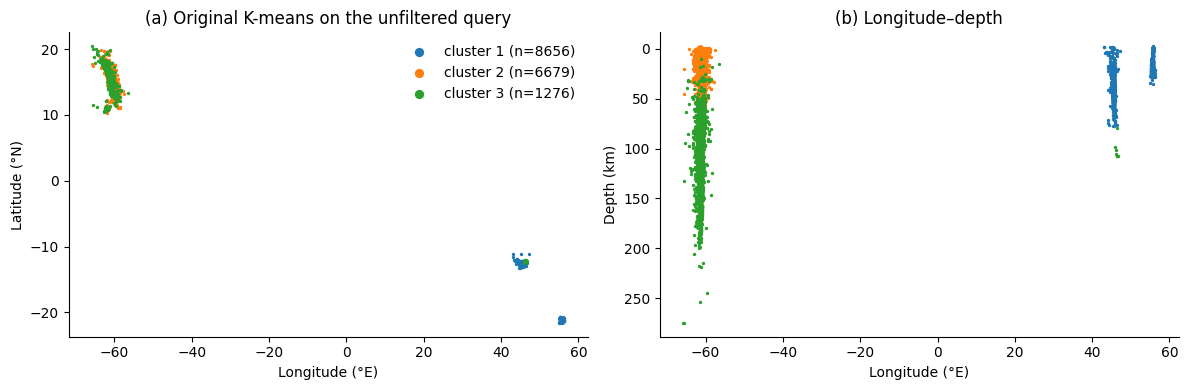

In [3]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

orig = raw[raw.time <= "2025-10-04"].copy()

cols0 = ["Magnitude", "Depth", "Latitude", "Longitude"]

# Conversion explicite en valeurs numériques
orig[cols0] = orig[cols0].apply(pd.to_numeric, errors="coerce")

# Suppression des valeurs manquantes et infinies
mask = np.isfinite(orig[cols0]).all(axis=1)
orig = orig.loc[mask].copy()

# Standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(orig[cols0])

# K-means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
orig["cluster"] = kmeans.fit_predict(X_scaled)

# Tableau diagnostique
diag = pd.concat([
    orig.groupby("cluster").agg(
        n=("time", "size"),
        depth_mean=("Depth", "mean"),
        depth_max=("Depth", "max"),
        lon_min=("Longitude", "min"),
        lon_max=("Longitude", "max")
    ).round(1),
    pd.crosstab(orig.cluster, orig.region)
], axis=1)

display(diag)

print(
    "Corrélation latitude-longitude dans le fichier mélangé :",
    round(np.corrcoef(raw.Latitude, raw.Longitude)[0, 1], 3)
)

# Visualisation
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for c, g in orig.groupby("cluster"):
    ax[0].scatter(
        g.Longitude, g.Latitude,
        s=2, label=f"cluster {c+1} (n={len(g)})"
    )
    ax[1].scatter(g.Longitude, g.Depth, s=2)

ax[0].legend(markerscale=4, frameon=False)
ax[0].set_xlabel("Longitude (°E)")
ax[0].set_ylabel("Latitude (°N)")

ax[1].invert_yaxis()
ax[1].set_xlabel("Longitude (°E)")
ax[1].set_ylabel("Depth (km)")

ax[0].set_title("(a) Original K-means on the unfiltered query")
ax[1].set_title("(b) Longitude–depth")

plt.tight_layout()
plt.savefig(f"{OUT}/Fig_diag_original_clusters.png", dpi=150)
plt.show()

## 2. Contrôle qualité du sous-catalogue de Mayotte

Étapes, dans cet ordre :
1. doublons exacts ;
2. **quasi-doublons** : temps d'origine distants d'au plus 1 min, épicentres à moins de 5 km, écart de magnitude inférieur à 0,3 (même séisme publié deux fois) ;
3. fenêtre d'étude 12,3–13,3°S × 44,9–46,1°E ;
4. suppression des profondeurs négatives (au-dessus du niveau de la mer : solutions à profondeur fixée ou ratées) ;
5. signalement (sans suppression) des profondeurs supérieures à 60 km, mal contraintes par un réseau essentiellement terrestre.

In [5]:
m = raw[raw.region == "Mayotte (REVOSIMA)"].sort_values("time").reset_index(drop=True)
qc = {"Mayotte region box": len(m)}
m = m.drop_duplicates(["time", "Latitude", "Longitude", "Depth", "Magnitude"]); qc["after exact duplicates"] = len(m)

m["x_km"] = (m.Longitude - LON0) * KX
m["y_km"] = (m.Latitude - LAT0) * KY
tmin = m.time.values.astype("datetime64[m]").astype(np.int64)
xyM = m[["x_km", "y_km", "Magnitude"]].values
drop = np.zeros(len(m), bool)
for i in range(len(m)):
    if drop[i]: continue
    j = i + 1
    while j < len(m) and tmin[j] - tmin[i] <= 1:
        if not drop[j] and np.hypot(*(xyM[i, :2] - xyM[j, :2])) < 5 and abs(xyM[i, 2] - xyM[j, 2]) < 0.3:
            drop[j] = True
        j += 1
m = m[~drop]; qc["after near-duplicates"] = len(m)
m = m[m.Latitude.between(*WINDOW["lat"]) & m.Longitude.between(*WINDOW["lon"])]; qc["after study window"] = len(m)
qc["negative depths removed"] = int((m.Depth < 0).sum())
m = m[m.Depth >= 0].copy(); qc["final catalogue"] = len(m)
m["deep_flag"] = m.Depth > 60; qc["depth > 60 km (flagged)"] = int(m.deep_flag.sum())
m = m.reset_index(drop=True)
display(pd.Series(qc, name="events"))
print("Période :", m.time.min(), "→", m.time.max())

Mayotte region box         6466
after exact duplicates     6466
after near-duplicates      6421
after study window         6346
negative depths removed       6
final catalogue            6329
depth > 60 km (flagged)      21
Name: events, dtype: int64

Période : 2021-03-01 00:43:00 → 2025-09-30 07:25:00


## 3. Magnitude de complétude et valeur b

* $M_c$ est estimée par la **courbure maximale + 0,2** (MAXC+0.2), sur tout le catalogue, par semestre et dans des fenêtres glissantes de 400 événements (pas de 100), avec 200 rééchantillonnages bootstrap par fenêtre.
* $b$ est estimée par **maximum de vraisemblance** (Aki–Utsu, magnitudes continues), avec l'écart-type de Shi & Bolt (1982).
* Le seuil retenu pour toutes les analyses de taux est le plus petit multiple de 0,1 dépassé par 95 % des estimations glissantes.

MAXC+0.2 = 1.50, b = 0.705 ± 0.009 (n = 3406)
Mc(t) entre 1.13 et 1.93 ; seuil retenu Mc = 1.7


,period,n,Mc,b,se,n_geMc
0,2021-H1,1144,1.5,0.80,0.03,636
1,2021-H2,1286,1.5,0.70,0.02,749
2,2022-H1,934,1.5,0.67,0.02,493
3,2022-H2,676,1.1,0.65,0.02,509
4,2023-H1,458,1.2,0.59,0.02,325
5,2023-H2,333,1.3,0.57,0.03,222
6,2024-H1,221,1.5,0.51,0.03,145
7,2024-H2,340,1.2,0.59,0.03,235
8,2025-H1,634,1.3,0.67,0.03,361
9,2025-H2,303,1.9,0.90,0.07,95


Test GFT : R maximal = 85.7 % (jamais ≥ 90 %) → FMD courbée, b non interprété en absolu


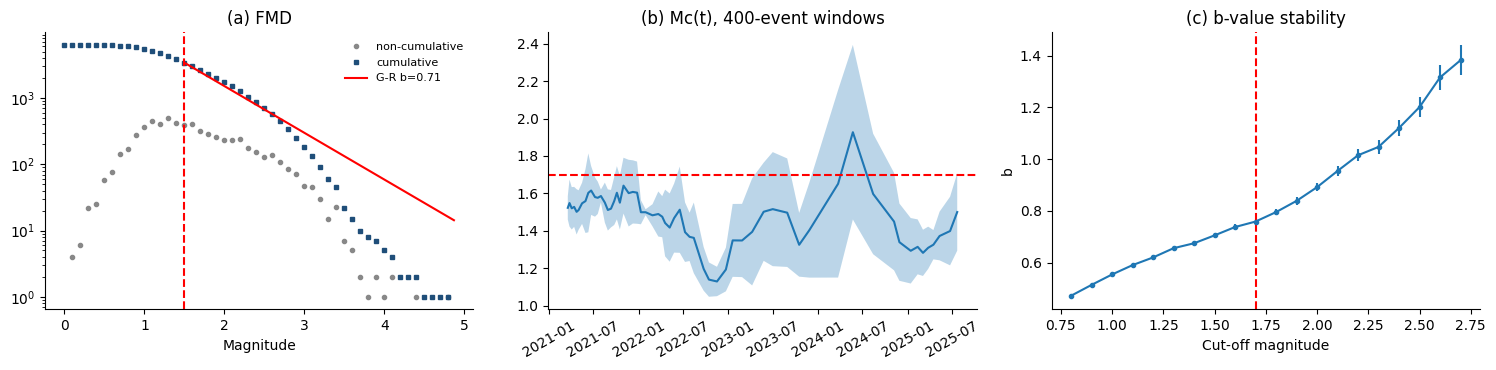

2613 événements avec M ≥ 1.7 utilisés pour les analyses de taux, le clustering et le lissage


In [6]:
def mc_maxc(M, dm=0.1, corr=0.2):
    bins = np.arange(np.floor(M.min() * 10) / 10, M.max() + dm, dm)
    h, e = np.histogram(M, bins)
    return e[np.argmax(h)] + corr

def b_aki(M, mc):
    s = M[M >= mc - 1e-9]
    b = np.log10(np.e) / (s.mean() - mc)
    return b, 2.3 * b ** 2 * s.std(ddof=1) / np.sqrt(len(s)), len(s)

M = m.Magnitude.values
mc_global = mc_maxc(M); b_g, sb_g, n_g = b_aki(M, mc_global)
print(f"MAXC+0.2 = {mc_global:.2f}, b = {b_g:.3f} ± {sb_g:.3f} (n = {n_g})")

rng = np.random.default_rng(SEED); rows = []
for s0 in range(0, len(m) - 400 + 1, 100):
    Mw = M[s0:s0 + 400]; boots = [mc_maxc(rng.choice(Mw, 400)) for _ in range(200)]
    rows.append(dict(t_mid=m.time.iloc[s0 + 200], Mc=np.mean(boots), sd=np.std(boots)))
mcT = pd.DataFrame(rows)
MC = float(np.ceil(max(mc_global, mcT.Mc.quantile(0.95)) * 10) / 10)
print(f"Mc(t) entre {mcT.Mc.min():.2f} et {mcT.Mc.max():.2f} ; seuil retenu Mc = {MC}")

m["half"] = m.time.dt.year.astype(str) + "-H" + np.where(m.time.dt.month <= 6, "1", "2")
half = []
for h, g in m.groupby("half"):
    if len(g) < 100: continue
    mch = mc_maxc(g.Magnitude.values); bh, sbh, nh = b_aki(g.Magnitude.values, mch)
    half.append(dict(period=h, n=len(g), Mc=round(mch, 2), b=round(bh, 2), se=round(sbh, 2), n_geMc=nh))
display(pd.DataFrame(half))

bvm = []
for mc in np.arange(0.8, 2.75, 0.1):
    s_ = M[M >= mc - 1e-9]; b_, sb_, n_ = b_aki(M, mc); a_ = np.log10(n_) + b_ * mc
    bins_ = np.arange(mc, s_.max() + 0.1, 0.1); obs_, _ = np.histogram(s_, bins_)
    cdf_ = 10 ** (a_ - b_ * bins_); pred_ = cdf_[:-1] - cdf_[1:]
    bvm.append(dict(cutoff=round(mc, 1), n=n_, b=b_, se=sb_, GFT_R=100 - 100 * np.abs(obs_ - pred_).sum() / obs_.sum()))
bvm = pd.DataFrame(bvm)
print(f"Test GFT : R maximal = {bvm.GFT_R.max():.1f} % (jamais ≥ 90 %) → FMD courbée, b non interprété en absolu")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
bins = np.arange(0, M.max() + 0.1, 0.1); h, e = np.histogram(M, bins)
ax[0].semilogy(e[:-1], h, "o", ms=3, color="#888", label="non-cumulative")
ax[0].semilogy(e[:-1], h[::-1].cumsum()[::-1], "s", ms=3, color="#1f4e79", label="cumulative")
xx = np.linspace(mc_global, M.max(), 50); ax[0].semilogy(xx, 10 ** (np.log10(n_g) + b_g * mc_global - b_g * xx), "r-", label=f"G-R b={b_g:.2f}")
ax[0].axvline(mc_global, ls="--", color="r"); ax[0].legend(frameon=False, fontsize=8); ax[0].set_xlabel("Magnitude"); ax[0].set_title("(a) FMD")
ax[1].plot(mcT.t_mid, mcT.Mc); ax[1].fill_between(mcT.t_mid, mcT.Mc - mcT.sd, mcT.Mc + mcT.sd, alpha=.3)
ax[1].axhline(MC, ls="--", color="r"); ax[1].set_title("(b) Mc(t), 400-event windows"); ax[1].tick_params(axis="x", rotation=30)
ax[2].errorbar(bvm.cutoff, bvm.b, bvm.se, fmt="o-", ms=3); ax[2].axvline(MC, ls="--", color="r")
ax[2].set_xlabel("Cut-off magnitude"); ax[2].set_ylabel("b"); ax[2].set_title("(c) b-value stability")
plt.tight_layout(); plt.savefig(f"{OUT}/Fig_Mc.png", dpi=150); plt.show()

c = m[m.Magnitude >= MC].copy().reset_index(drop=True)
print(f"{len(c)} événements avec M ≥ {MC} utilisés pour les analyses de taux, le clustering et le lissage")

## 4. Carte de la zone d'étude (réponse au reviewer 1)
La couleur code la profondeur et la taille la magnitude ; une coupe est–ouest en profondeur est ajoutée sous la carte.
Le script `fig1_map.R` produit la version de publication sur le trait de côte (`976_Commune.shp`).

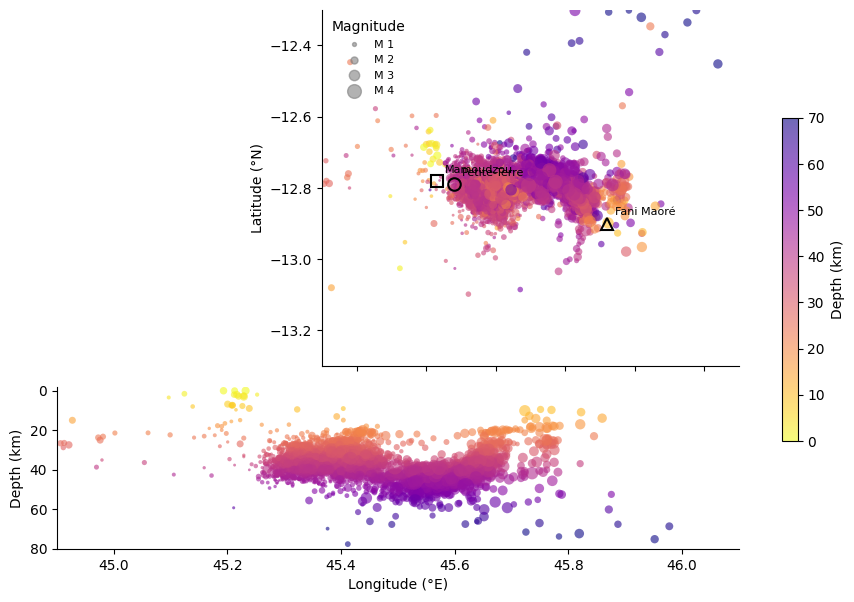

In [7]:
mm = m.sort_values("Magnitude"); size = 2 + 6 * mm.Magnitude.clip(0, 5) ** 2
fig = plt.figure(figsize=(11, 7)); gs = fig.add_gridspec(2, 1, height_ratios=[2.2, 1], hspace=.08)
a1 = fig.add_subplot(gs[0]); a2 = fig.add_subplot(gs[1], sharex=a1)
sc = a1.scatter(mm.Longitude, mm.Latitude, s=size, c=mm.Depth.clip(0, 70), cmap="plasma_r", alpha=.6, edgecolors="none")
a2.scatter(mm.Longitude, mm.Depth, s=size, c=mm.Depth.clip(0, 70), cmap="plasma_r", alpha=.6, edgecolors="none")
for (lo, la), lab, mk in [(FANI, "Fani Maoré", "^"), (MAMOUDZOU, "Mamoudzou", "s"), (PETITE_TERRE, "Petite-Terre", "o")]:
    a1.plot(lo, la, mk, ms=9, mfc="none", mec="k", mew=1.5); a1.annotate(lab, (lo, la), xytext=(6, 6), textcoords="offset points", fontsize=8)
a1.set_xlim(*WINDOW["lon"]); a1.set_ylim(*WINDOW["lat"]); a1.set_aspect(1 / np.cos(np.radians(12.8))); a1.set_ylabel("Latitude (°N)")
plt.setp(a1.get_xticklabels(), visible=False)
a2.set_ylim(80, -2); a2.set_ylabel("Depth (km)"); a2.set_xlabel("Longitude (°E)")
fig.colorbar(sc, ax=[a1, a2], shrink=.6).set_label("Depth (km)")
for Mv in [1, 2, 3, 4]: a1.scatter([], [], s=2 + 6 * Mv ** 2, c="grey", alpha=.6, label=f"M {Mv}")
a1.legend(title="Magnitude", loc="upper left", frameon=False, fontsize=8)
plt.savefig(f"{OUT}/Fig_map.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Clustering hypocentral (réponse au commentaire 3 du reviewer 2)

* **Variables** : $(x, y, z)$ en km. Toutes ont la même unité, elles ne sont donc **pas** standardisées (la standardisation étirerait artificiellement l'axe vertical). La magnitude est exclue pour que les classes décrivent des sources et non des tailles d'événements.
* **Choix de K** : $K = 2, \dots, 10$, critères silhouette, Calinski–Harabasz et Davies–Bouldin.
* **Initialisation** : k-means++, 50 relances.
* **Stabilité** : ARI sur 100 initialisations uniques ; ARI et coefficients de Jaccard par classe (Hennig, 2007) sur 200 rééchantillonnages bootstrap.
* **Sensibilité** : variables standardisées $(x, y, z)$, puis $(x, y, z, M)$.

,K,inertia,silhouette,CH,DB
0,2,331072.390,0.545,3004.206,0.675
1,3,247618.384,0.435,2447.394,0.862
2,4,205463.171,0.440,2144.042,0.740
3,5,178034.333,0.450,1955.503,0.743
4,6,150846.458,0.455,1939.624,0.743
5,7,131343.288,0.386,1920.160,0.856
6,8,116758.282,0.343,1897.209,0.936
7,9,107023.295,0.351,1839.981,0.871
8,10,100024.117,0.353,1769.552,0.803


K retenu (silhouette maximale) : 2
Sensibilité, standardised (x,y,z) : silhouettes de 0.32 à 0.42
Sensibilité, standardised (x,y,z,M) : silhouettes de 0.25 à 0.33
ARI sur 100 initialisations uniques : moyenne 0.989, minimum 0.015
ARI bootstrap : moyenne 0.992, 5e percentile 0.985
Jaccard par classe : {2: np.float64(0.997), 1: np.float64(0.994)}


,n,lon_c,lon_p05,lon_p95,depth_mean,depth_p05,depth_p95,M_mean,M_max,share_%,silhouette
cluster,,,,,,,,,,,
1,919,45.38,45.31,45.46,35.11,24.83,43.34,2.01,4.48,35.2,0.566
2,1694,45.61,45.52,45.69,41.24,27.59,51.37,2.42,4.87,64.8,0.533


cluster,1,2
share by year,,
2021,0.464,0.536
2022,0.330,0.670
2023,0.244,0.756
2024,0.246,0.754
2025,0.245,0.755


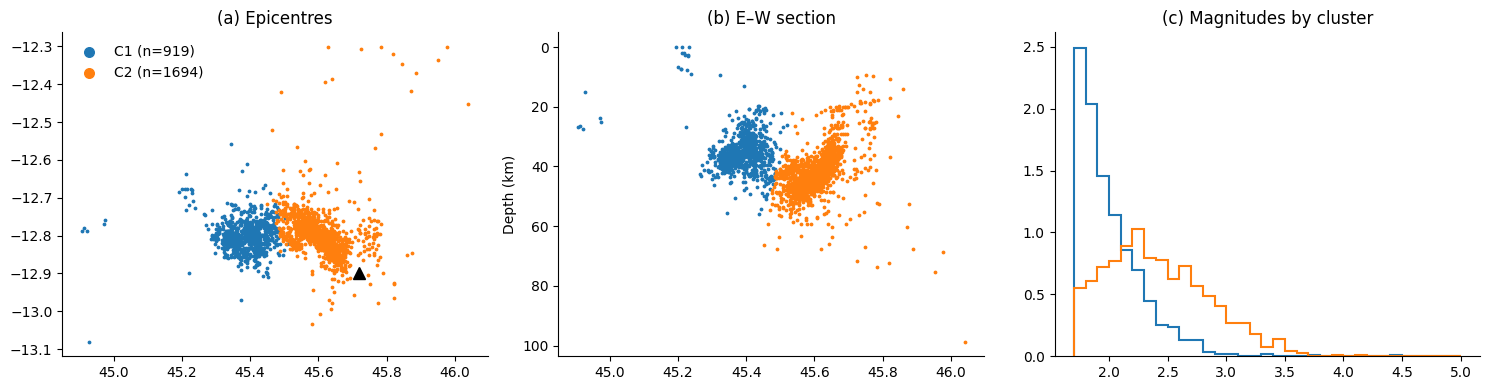

In [8]:
X = c[["x_km", "y_km", "Depth"]].values
sel = []
for k in range(2, 11):
    km = KMeans(k, init="k-means++", n_init=50, random_state=SEED).fit(X)
    sel.append(dict(K=k, inertia=km.inertia_, silhouette=silhouette_score(X, km.labels_),
                    CH=calinski_harabasz_score(X, km.labels_), DB=davies_bouldin_score(X, km.labels_)))
sel = pd.DataFrame(sel).round(3); display(sel)
Kopt = int(sel.K[sel.silhouette.idxmax()]); print("K retenu (silhouette maximale) :", Kopt)

for name, cols in {"standardised (x,y,z)": ["x_km", "y_km", "Depth"], "standardised (x,y,z,M)": ["x_km", "y_km", "Depth", "Magnitude"]}.items():
    Z = StandardScaler().fit_transform(c[cols])
    s = [silhouette_score(Z, KMeans(k, n_init=20, random_state=SEED).fit_predict(Z)) for k in range(2, 11)]
    print(f"Sensibilité, {name} : silhouettes de {min(s):.2f} à {max(s):.2f}")

ref = KMeans(Kopt, init="k-means++", n_init=50, random_state=SEED).fit(X)
order = np.argsort(ref.cluster_centers_[:, 0]); relab = {o: i + 1 for i, o in enumerate(order)}
c["cluster"] = [relab[l] for l in ref.labels_]

ari_seed = [adjusted_rand_score(ref.labels_, KMeans(Kopt, n_init=1, random_state=s).fit_predict(X)) for s in range(100)]
rng = np.random.default_rng(1); ari_boot, jac = [], {k: [] for k in range(Kopt)}
for b in range(200):
    idx = rng.choice(len(X), len(X)); lab_b = KMeans(Kopt, n_init=10, random_state=b).fit(X[idx]).predict(X)
    ari_boot.append(adjusted_rand_score(ref.labels_, lab_b))
    for k in range(Kopt):
        A = ref.labels_ == k
        jac[k].append(max((A & (lab_b == j)).sum() / (A | (lab_b == j)).sum() for j in range(Kopt)))
print(f"ARI sur 100 initialisations uniques : moyenne {np.mean(ari_seed):.3f}, minimum {np.min(ari_seed):.3f}")
print(f"ARI bootstrap : moyenne {np.mean(ari_boot):.3f}, 5e percentile {np.quantile(ari_boot, .05):.3f}")
print("Jaccard par classe :", {relab[k]: round(np.mean(v), 3) for k, v in jac.items()})

q05, q95 = (lambda s: s.quantile(.05)), (lambda s: s.quantile(.95))
tab_cl = c.groupby("cluster").agg(n=("time", "size"), lon_c=("Longitude", "mean"), lon_p05=("Longitude", q05), lon_p95=("Longitude", q95),
    depth_mean=("Depth", "mean"), depth_p05=("Depth", q05), depth_p95=("Depth", q95), M_mean=("Magnitude", "mean"), M_max=("Magnitude", "max")).round(2)
tab_cl["share_%"] = (100 * tab_cl.n / tab_cl.n.sum()).round(1)
tab_cl["silhouette"] = pd.Series(silhouette_samples(X, c.cluster)).groupby(c.cluster).mean().round(3)
display(tab_cl)
display(pd.crosstab(c.time.dt.year, c.cluster, normalize="index").round(3).rename_axis("share by year"))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for k in range(1, Kopt + 1):
    g = c[c.cluster == k]
    ax[0].scatter(g.Longitude, g.Latitude, s=3, label=f"C{k} (n={len(g)})"); ax[1].scatter(g.Longitude, g.Depth, s=3)
    ax[2].hist(g.Magnitude, bins=np.arange(MC, 5.1, .1), histtype="step", density=True, lw=1.5)
ax[0].plot(*FANI, "k^", ms=9); ax[0].legend(markerscale=4, frameon=False); ax[0].set_title("(a) Epicentres")
ax[1].invert_yaxis(); ax[1].set_title("(b) E–W section"); ax[1].set_ylabel("Depth (km)"); ax[2].set_title("(c) Magnitudes by cluster")
plt.tight_layout(); plt.savefig(f"{OUT}/Fig_clusters.png", dpi=150); plt.show()

## 6. Lissage exponentiel (Holt–Winters / ETS) des comptages hebdomadaires

* **Série** : nombre hebdomadaire d'événements avec $M \ge M_c$ (semaines terminées le dimanche ; premières et dernières semaines incomplètes retirées).
* **Modèles** : SES, Holt, Holt amorti, Holt–Winters additif, multiplicatif (ajusté sur $Y+1$ à cause des semaines nulles) et additif amorti, période saisonnière $m = 52$.
* **Estimation** : minimisation de la somme des carrés des erreurs à un pas sur une **fenêtre commune** (à partir de la semaine 105), pour que les AICc soient comparables. Les états initiaux sont tirés de la décomposition classique des deux premières saisons et comptés dans $k$.
* **Évaluation** : les 52 dernières semaines ne servent jamais à l'ajustement. On les prévoit (i) de 1 à 52 semaines depuis la fin de l'apprentissage, (ii) à un pas avec origine glissante. Critères MAE, RMSE et MASE, avec les références naïve, naïve saisonnière et moyenne de la dernière année.

238 semaines, du 2021-03-14 au 2025-09-28 ; 9 semaines sans événement


time,2021,2022,2023,2024,2025
events M>=1.7,1037,612,340,260,364


,model,alpha,beta,gamma,phi,k,AICc,MAE_h52,RMSE_h52,MAE_1,RMSE_1,MASE_1
0,"SES (N,N)",0.084,NaN,NaN,NaN,2.0,211.313,4.171,5.392,3.284,4.165,0.757
1,"Holt (A,N)",0.071,0.038,NaN,NaN,4.0,216.100,4.418,5.636,3.351,4.147,0.772
2,"Holt damped (Ad,N)",0.004,1.000,NaN,0.935,5.0,213.338,4.043,5.245,3.410,4.424,0.786
3,"HW additive (A,A,52)",0.039,0.067,0.539,NaN,57.0,634.097,5.090,6.465,4.626,5.628,1.066
4,"HW multiplicative (A,M,52)",0.067,0.038,0.284,NaN,57.0,601.812,4.828,6.110,4.086,4.869,0.941
5,"HW damped additive (Ad,A,52)",0.003,0.964,0.578,0.947,58.0,653.890,5.011,6.327,4.514,5.673,1.040
6,Naive,NaN,NaN,NaN,NaN,NaN,NaN,6.442,7.637,3.865,5.063,0.891
7,Seasonal naive,NaN,NaN,NaN,NaN,NaN,NaN,4.962,6.276,4.962,6.276,1.143
8,Mean of last year,NaN,NaN,NaN,NaN,NaN,NaN,4.106,5.315,4.106,5.315,0.946


Modèle retenu par l'AICc : SES (N,N)


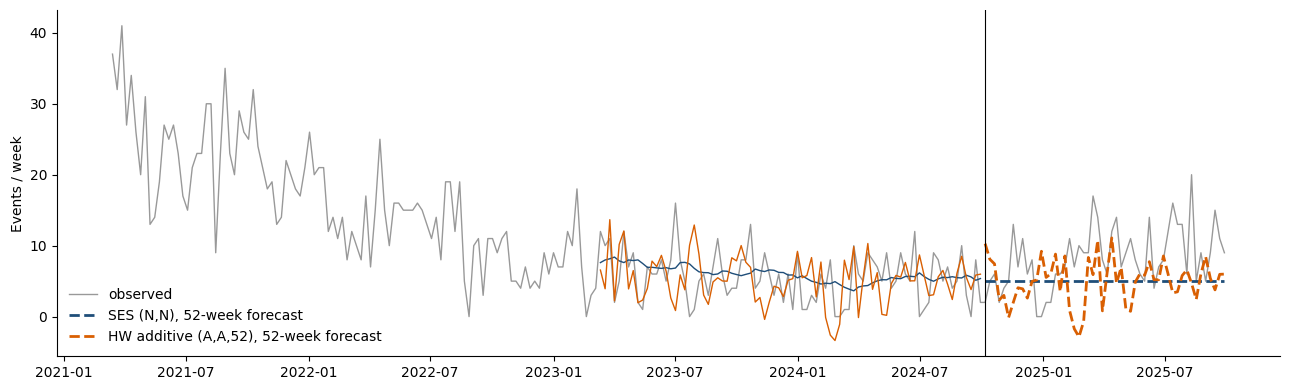

In [10]:
day0, day1 = m.time.min().normalize(), m.time.max().normalize() - pd.Timedelta(days=1)
daily = c.set_index("time").resample("D").size().reindex(pd.date_range(day0, day1, freq="D"), fill_value=0)
weekly = daily.resample("W-SUN").sum().iloc[1:-1]
print(f"{len(weekly)} semaines, du {weekly.index[0].date()} au {weekly.index[-1].date()} ; {int((weekly == 0).sum())} semaines sans événement")
display(c.groupby(c.time.dt.year).size().rename(f"events M>={MC}").to_frame().T)

def hw_init(y, trend, season, mper):
    if season:
        l0 = y[:mper].mean(); b0 = (y[mper:2 * mper].mean() - l0) / mper if trend else 0.0
        return l0, b0, list(y[:mper] - l0 if season == "add" else y[:mper] / l0)
    return y[0], (y[1] - y[0]) if trend else 0.0, None

def hw_filter(par, y, trend, damped, season, mper=52, h=0):
    a = par[0]; bb = par[1] if trend else 0; g = par[1 + trend] if season else 0; phi = par[-1] if damped else 1.0
    l, b, s = hw_init(y, trend, season, mper); fit = np.empty(len(y))
    for t in range(len(y)):
        st = s[t] if season else 0.0
        fit[t] = (l + phi * b) * st if season == "mul" else l + phi * b + st
        lp, bp = l, b
        if season == "mul": l = a * y[t] / st + (1 - a) * (lp + phi * bp)
        elif season == "add": l = a * (y[t] - st) + (1 - a) * (lp + phi * bp)
        else: l = a * y[t] + (1 - a) * (lp + phi * bp)
        if trend: b = bb * (l - lp) + (1 - bb) * phi * bp
        if season == "mul": s.append(g * y[t] / (lp + phi * bp) + (1 - g) * st)
        elif season == "add": s.append(g * (y[t] - lp - phi * bp) + (1 - g) * st)
    fc = []
    for k in range(1, h + 1):
        damp = sum(phi ** j for j in range(1, k + 1)) if trend else 0
        st = s[len(y) - mper + (k - 1) % mper] if season else 0.0
        fc.append((l + damp * b) * st if season == "mul" else l + damp * b + st)
    return fit, np.array(fc)

SPECS = {"SES (N,N)": (False, False, None), "Holt (A,N)": (True, False, None), "Holt damped (Ad,N)": (True, True, None),
         "HW additive (A,A,52)": (True, False, "add"), "HW multiplicative (A,M,52)": (True, False, "mul"),
         "HW damped additive (Ad,A,52)": (True, True, "add")}

def fit_hw(y, spec, mper=52):
    trend, damped, season = spec
    npar = 1 + trend + bool(season) + damped; start = 2 * mper
    bnds = [(1e-4, .9999)] * npar
    if damped: bnds[-1] = (.8, .98)
    yy = y + 1.0 if season == "mul" else y
    def sse(p):
        f, _ = hw_filter(p, yy, trend, damped, season, mper); e = yy[start:] - f[start:]
        return np.sum(e ** 2) if np.all(np.isfinite(e)) else 1e12
    best = min((optimize.minimize(sse, [a0, .05, .1, .95][:npar], bounds=bnds, method="L-BFGS-B") for a0 in (.1, .3, .6)), key=lambda r: r.fun)
    n = len(y) - start; k = npar + 1 + trend + (mper if season else 0)
    aic = n * np.log(best.fun / n) + 2 * k
    return dict(par=best.x, aicc=aic + 2 * k * (k + 1) / max(n - k - 1, 1), k=k, shift=1.0 if season == "mul" else 0.0, start=start)

y = weekly.values.astype(float); H = 52; ytr, yte = y[:-H], y[-H:]
scale = np.mean(np.abs(np.diff(ytr)))
metrics = lambda fc, one: dict(MAE_h52=np.mean(np.abs(yte - fc)), RMSE_h52=np.sqrt(np.mean((yte - fc) ** 2)),
                               MAE_1=np.mean(np.abs(yte - one)), RMSE_1=np.sqrt(np.mean((yte - one) ** 2)), MASE_1=np.mean(np.abs(yte - one)) / scale)
rows, fits = [], {}
for name, spec in SPECS.items():
    f = fit_hw(ytr, spec)
    _, fc = hw_filter(f["par"], ytr + f["shift"], *spec, h=H); fc -= f["shift"]
    one = np.array([hw_filter(f["par"], y[:len(ytr) + i] + f["shift"], *spec, h=1)[1][0] - f["shift"] for i in range(H)])
    fits[name] = (spec, f, fc)
    rows.append(dict(model=name, alpha=f["par"][0], beta=f["par"][1] if spec[0] else np.nan, gamma=f["par"][1 + spec[0]] if spec[2] else np.nan,
                     phi=f["par"][-1] if spec[1] else np.nan, k=f["k"], AICc=f["aicc"], **metrics(fc, one)))
for name, fc, one in [("Naive", np.repeat(ytr[-1], H), y[len(ytr) - 1:-1]), ("Seasonal naive", ytr[-52:], y[len(ytr) - 52:-52]),
                      ("Mean of last year", np.repeat(ytr[-52:].mean(), H), np.repeat(ytr[-52:].mean(), H))]:
    rows.append(dict(model=name, **metrics(fc, one)))
hw = pd.DataFrame(rows).round(3); display(hw)
print("Modèle retenu par l'AICc :", hw.dropna(subset=["AICc"]).sort_values("AICc").model.iloc[0])

fig, ax = plt.subplots(figsize=(13, 4)); ax.plot(weekly.index, y, color="#999", lw=1, label="observed")
for name, col in [("SES (N,N)", "#1f4e79"), ("HW additive (A,A,52)", "#d95f02")]:
    spec, f, fc = fits[name]; fit_tr, _ = hw_filter(f["par"], ytr + f["shift"], *spec)
    ax.plot(weekly.index[f["start"]:len(ytr)], fit_tr[f["start"]:] - f["shift"], color=col, lw=1)
    ax.plot(weekly.index[-H:], fc, color=col, lw=2, ls="--", label=f"{name}, 52-week forecast")
ax.axvline(weekly.index[-H], color="k", lw=.8); ax.legend(frameon=False); ax.set_ylabel("Events / week")
plt.tight_layout(); plt.savefig(f"{OUT}/Fig_holt_winters.png", dpi=150); plt.show()

## 7. Tests de saisonnalité annuelle et de cycle jour/nuit

**Saisonnalité annuelle.** On ajuste aux comptages journaliers un modèle log-linéaire quasi-Poisson, avec une tendance B-spline cubique (nœuds tous les 2 ans, puis tous les ans) et soit une harmonique annuelle, soit un facteur mois à 12 niveaux. Les termes saisonniers sont testés par un test $F$ sur la déviance, mise à l'échelle par la dispersion de Pearson.

**Test robuste au regroupement.** Test de Schuster sur le catalogue dé-clusterisé (fenêtres de Gardner–Knopoff).

**Jour/nuit.** Fraction d'événements entre 18 h et 6 h (heure locale UTC+3), par seuil de magnitude. Un effet physique persisterait au-dessus de tout seuil, alors qu'un **biais de détection** (bruit humain diurne) s'atténue quand le seuil augmente.

Harmonique annuelle (nœuds tous les 2 ans) : F = 0.13, p = 0.880, amplitude RR = 1.018, dispersion = 1.35
Harmonique annuelle (nœuds tous les 1 ans) : F = 0.52, p = 0.594, amplitude RR = 1.040, dispersion = 1.36
Facteur mois : F(11) = 1.28, p = 0.230


,0,1,2,3,4,5,6,7,8,9,10,11
month,1.00,2.000,3.000,4.000,5.000,6.000,7.000,8.000,9.000,10.000,11.000,12.000
RR,1.04,0.812,1.154,1.067,0.906,1.047,1.042,1.017,1.019,1.107,0.950,0.892
lo,1.04,0.617,0.915,0.846,0.716,0.832,0.829,0.806,0.801,0.872,0.738,0.691
hi,1.04,1.069,1.455,1.346,1.147,1.318,1.310,1.283,1.297,1.406,1.222,1.153


Catalogue dé-clusterisé : 170 événements ; Schuster annuel p = 0.302


,n,night_fraction,p
M<1,771.0,0.927,1.500821e-146
all,6329.0,0.789,0.000000e+00
M>=1.7,2613.0,0.667,3.565967e-66
M>=2,1744.0,0.628,8.701714e-27
M>=2.5,711.0,0.561,1.243000e-03
M>=3,182.0,0.522,6.039707e-01
M>=1.7 declustered,170.0,0.559,1.448310e-01


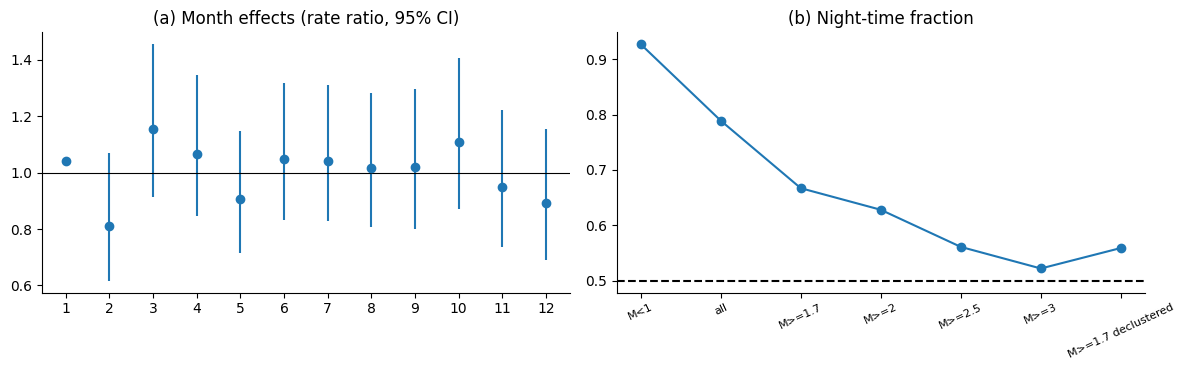

In [11]:
def bspline_basis(x, knots, deg=3):
    t = np.r_[[x.min()] * (deg + 1), knots, [x.max()] * (deg + 1)]; nb = len(t) - deg - 1
    return np.column_stack([BSpline(t, np.eye(nb)[i], deg)(x) for i in range(nb)])

def poisson_irls(Xd, yv, it=100):
    beta = np.linalg.lstsq(Xd, np.log(yv + .5), rcond=None)[0]
    for _ in range(it):
        eta = Xd @ beta; mu = np.exp(eta); z = eta + (yv - mu) / mu
        nb = np.linalg.solve((Xd.T * mu) @ Xd + 1e-8 * np.eye(Xd.shape[1]), (Xd.T * mu) @ z)
        if np.max(np.abs(nb - beta)) < 1e-9: beta = nb; break
        beta = nb
    mu = np.exp(Xd @ beta)
    dev = 2 * np.sum(np.where(yv > 0, yv * np.log(np.where(yv > 0, yv, 1) / mu), 0) - (yv - mu))
    return beta, mu, dev, np.linalg.inv((Xd.T * mu) @ Xd)

yd = daily.values.astype(float); tt = np.arange(len(yd)) / 365.25; doy = daily.index.dayofyear.values / 365.25
for step in (2.0, 1.0):
    B = bspline_basis(tt, np.arange(step, tt.max() - .25, step))
    X1 = np.column_stack([B, np.sin(2 * np.pi * doy), np.cos(2 * np.pi * doy)])
    _, _, d0, _ = poisson_irls(B, yd); b1, mu1, d1, _ = poisson_irls(X1, yd)
    phi = np.sum((yd - mu1) ** 2 / mu1) / (len(yd) - X1.shape[1]); F = (d0 - d1) / 2 / phi
    print(f"Harmonique annuelle (nœuds tous les {step:g} ans) : F = {F:.2f}, p = {stats.f.sf(F, 2, len(yd) - X1.shape[1]):.3f}, "
          f"amplitude RR = {np.exp(np.hypot(b1[-2], b1[-1])):.3f}, dispersion = {phi:.2f}")

B = bspline_basis(tt, np.arange(2.0, tt.max() - .25, 2.0)); mon = daily.index.month.values
Dm = np.column_stack([(mon == k).astype(float) for k in range(2, 13)])
bM, muM, dM, covM = poisson_irls(np.column_stack([B, Dm]), yd); _, _, d0, _ = poisson_irls(B, yd)
phiM = np.sum((yd - muM) ** 2 / muM) / (len(yd) - B.shape[1] - 11); FM = (d0 - dM) / 11 / phiM
coef = np.r_[0, bM[-11:]]; se = np.r_[0, np.sqrt(np.diag(covM)[-11:] * phiM)]; cc_ = coef - coef.mean()
months = pd.DataFrame(dict(month=range(1, 13), RR=np.exp(cc_), lo=np.exp(cc_ - 1.96 * se), hi=np.exp(cc_ + 1.96 * se))).round(3)
print(f"Facteur mois : F(11) = {FM:.2f}, p = {stats.f.sf(FM, 11, len(yd) - B.shape[1] - 11):.3f}")
display(months.T)

def gk_decluster(df):
    df = df.sort_values("time").reset_index(drop=True); td = (df.time - df.time.min()).dt.total_seconds().values / 86400
    xk, yk, Mk = df.x_km.values, df.y_km.values, df.Magnitude.values; keep = np.ones(len(df), bool)
    for i in np.argsort(-Mk):
        if not keep[i]: continue
        L = 10 ** (0.1238 * Mk[i] + 0.983); T = 10 ** (0.5409 * Mk[i] - 0.547) if Mk[i] < 6.5 else 10 ** (0.032 * Mk[i] + 2.7389)
        s_ = (np.abs(td - td[i]) <= T) & (np.hypot(xk - xk[i], yk - yk[i]) <= L) & (Mk <= Mk[i]); s_[i] = False; keep[s_] = False
    return df[keep]

schuster = lambda ph: float(np.exp(-np.abs(np.exp(1j * ph).sum()) ** 2 / len(ph)))
dc = gk_decluster(c)
print(f"Catalogue dé-clusterisé : {len(dc)} événements ; Schuster annuel p = {schuster(2*np.pi*dc.time.dt.dayofyear.values/365.25):.3f}")

def night(df):
    hh = (df.time + pd.Timedelta(hours=UTC_OFFSET_H)).dt.hour; nf = ((hh >= 18) | (hh < 6)).mean()
    return dict(n=len(df), night_fraction=round(nf, 3), p=stats.binomtest(int(round(nf * len(df))), len(df), .5).pvalue)
dn = pd.DataFrame({lab: night(df_) for lab, df_ in [("M<1", m[m.Magnitude < 1]), ("all", m), (f"M>={MC}", c), ("M>=2", m[m.Magnitude >= 2]),
                   ("M>=2.5", m[m.Magnitude >= 2.5]), ("M>=3", m[m.Magnitude >= 3]), (f"M>={MC} declustered", dc)]}).T
display(dn)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].errorbar(months.month, months.RR, [months.RR - months.lo, months.hi - months.RR], fmt="o"); ax[0].axhline(1, color="k", lw=.8)
ax[0].set_xticks(range(1, 13)); ax[0].set_title("(a) Month effects (rate ratio, 95% CI)")
ax[1].plot(range(len(dn)), dn.night_fraction.astype(float), "o-"); ax[1].axhline(.5, ls="--", color="k")
ax[1].set_xticks(range(len(dn))); ax[1].set_xticklabels(dn.index, rotation=25, fontsize=8); ax[1].set_title("(b) Night-time fraction")
plt.tight_layout(); plt.savefig(f"{OUT}/Fig_periodicity.png", dpi=150); plt.show()

## 8. Lisseur à noyau spatio-temporel et validation croisée par blocs (commentaire 5)

Distance adimensionnelle : $d_i^2 = \|\mathbf s_i - \mathbf s_0\|^2 / h_s^2 + (t_i - t_0)^2 / h_t^2$, avec $\mathbf s$ en km, $t$ en jours et le noyau $K(d) = e^{-d^2/2}$.
Le rapport $c = h_s / h_t$ (km/jour) donne l'**échelle espace–temps**. Une variante IDW utilise des poids $(\|\Delta \mathbf s\|^2 + c^2 \Delta t^2 + \varepsilon^2)^{-p/2}$.

Quatre schémas de validation croisée à 5 plis : aléatoire, **blocs temporels**, **blocs spatiaux** (K-means sur $(x, y)$) et **chaînage avant** (on ne prédit qu'à partir du passé).

Grille complète évaluée en 31.0 s


,scheme,model,par1,par2,RMSE,MAE,RMSE_base,skill_pct
0,random,Gaussian,3.0,90.000,0.3805,0.2939,0.4382,13.1613
1,random,IDW,2.0,0.030,0.3837,0.3008,0.4382,12.4366
2,temporal_block,Gaussian,3.0,1000.000,0.3861,0.2992,0.4388,11.9905
3,temporal_block,IDW,2.0,0.003,0.3823,0.2984,0.4388,12.8705
4,spatial_block,Gaussian,5.0,1000.000,0.3999,0.3133,0.4777,16.2894
5,spatial_block,IDW,3.0,0.003,0.3997,0.3141,0.4777,16.3336
6,forward_chaining,Gaussian,5.0,1000.000,0.3979,0.3141,0.4485,11.2889
7,forward_chaining,IDW,2.0,0.003,0.3948,0.3118,0.4485,11.9781


Optimisme de la CV aléatoire : avec ses fenêtres (h_s=3 km, h_t=90 j), l'erreur devient :
  temporal_block    RMSE = 0.4000 (meilleure possible : 0.3861)
  spatial_block     RMSE = 0.4133 (meilleure possible : 0.3999)
  forward_chaining  RMSE = 0.4159 (meilleure possible : 0.3979)
Fenêtres finales (CV par blocs temporels) : h_s = 3 km, h_t = 1000 jours, c = 0.003 km/jour


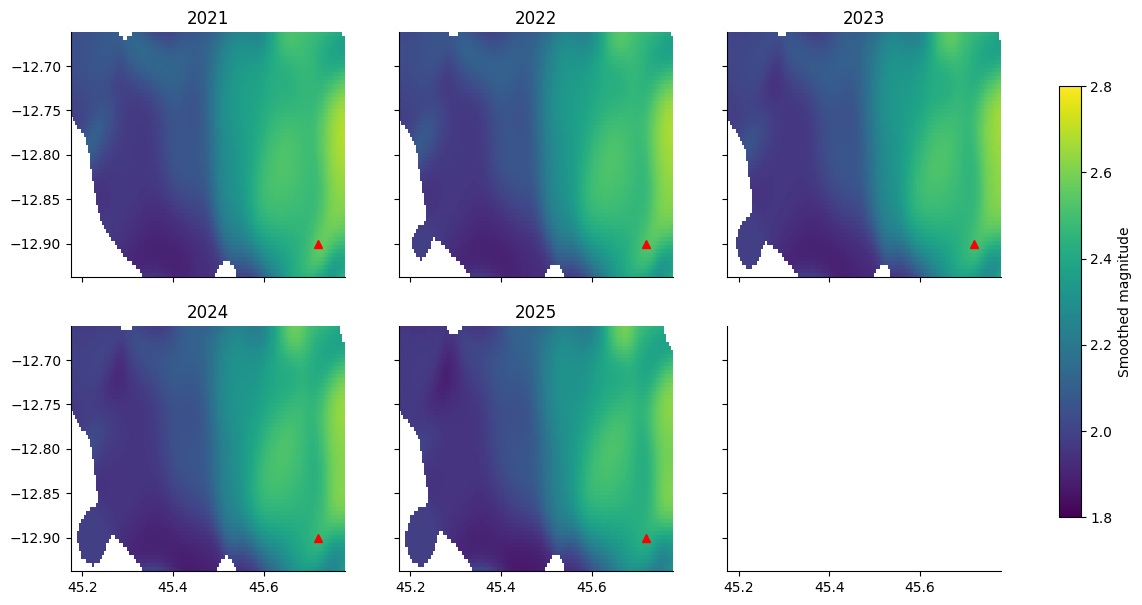

In [12]:
d = c.sort_values("time").reset_index(drop=True)
xs, ys, zs = d.x_km.values, d.y_km.values, d.Magnitude.values
ts = ((d.time - d.time.min()).dt.total_seconds() / 86400).values; N = len(d)
DS2 = (xs[:, None] - xs[None]) ** 2 + (ys[:, None] - ys[None]) ** 2
DT2 = (ts[:, None] - ts[None]) ** 2

def folds(scheme, k=5):
    if scheme == "random": lab = np.random.default_rng(SEED).permutation(N) % k
    elif scheme == "spatial_block": lab = KMeans(k, n_init=20, random_state=SEED).fit_predict(np.c_[xs, ys])
    else: lab = np.minimum(np.arange(N) * k // N, k - 1)
    if scheme == "forward_chaining": return [(np.where(lab < f)[0], np.where(lab == f)[0]) for f in range(1, k)]
    return [(np.where(lab != f)[0], np.where(lab == f)[0]) for f in range(k)]

def pred_gauss(tr, te, hs, ht):
    E = np.zeros((len(te), len(tr)))
    if np.isfinite(hs): E += DS2[np.ix_(te, tr)] / hs ** 2
    if np.isfinite(ht): E += DT2[np.ix_(te, tr)] / ht ** 2
    W = np.exp(-.5 * E); sw = W.sum(1)
    return np.where(sw > 1e-12, W @ zs[tr] / np.maximum(sw, 1e-300), zs[tr].mean())

def pred_idw(tr, te, p, cc):
    W = (DS2[np.ix_(te, tr)] + cc ** 2 * DT2[np.ix_(te, tr)] + .01) ** (-p / 2); return W @ zs[tr] / W.sum(1)

def score(fn, F):
    e = np.concatenate([zs[te] - fn(tr, te) for tr, te in F]); return np.sqrt(np.mean(e ** 2)), np.mean(np.abs(e))

HS, HT = [.5, 1, 2, 3, 5, 10, np.inf], [3, 10, 30, 90, 180, 365, 1000, np.inf]
t0 = time.time(); cv = []
for scheme in ["random", "temporal_block", "spatial_block", "forward_chaining"]:
    F = folds(scheme); rb, mb = score(lambda tr, te: np.repeat(zs[tr].mean(), len(te)), F)
    cv.append(dict(scheme=scheme, model="baseline", p1=np.nan, p2=np.nan, RMSE=rb, MAE=mb))
    for hs in HS:
        for ht in HT:
            if np.isfinite(hs) or np.isfinite(ht):
                r_, a_ = score(lambda tr, te: pred_gauss(tr, te, hs, ht), F); cv.append(dict(scheme=scheme, model="Gaussian", p1=hs, p2=ht, RMSE=r_, MAE=a_))
    for p in (1, 2, 3):
        for cc in (.003, .01, .03, .1, .3, 1.):
            r_, a_ = score(lambda tr, te: pred_idw(tr, te, p, cc), F); cv.append(dict(scheme=scheme, model="IDW", p1=p, p2=cc, RMSE=r_, MAE=a_))
cv = pd.DataFrame(cv); print(f"Grille complète évaluée en {time.time() - t0:.1f} s")
best = []
for (scheme, mod), g in cv[cv.model != "baseline"].groupby(["scheme", "model"], sort=False):
    b = g.sort_values("RMSE").iloc[0]; base = cv[(cv.scheme == scheme) & (cv.model == "baseline")].iloc[0]
    best.append(dict(scheme=scheme, model=mod, par1=b.p1, par2=b.p2, RMSE=b.RMSE, MAE=b.MAE, RMSE_base=base.RMSE, skill_pct=100 * (1 - b.RMSE / base.RMSE)))
best = pd.DataFrame(best).round(4); display(best)
gb = cv[cv.model == "Gaussian"]; br = gb[gb.scheme == "random"].sort_values("RMSE").iloc[0]
print(f"Optimisme de la CV aléatoire : avec ses fenêtres (h_s={br.p1:g} km, h_t={br.p2:g} j), l'erreur devient :")
for scheme in ["temporal_block", "spatial_block", "forward_chaining"]:
    gg = gb[gb.scheme == scheme]
    print(f"  {scheme:17s} RMSE = {gg[(gg.p1 == br.p1) & (gg.p2 == br.p2)].RMSE.iloc[0]:.4f} (meilleure possible : {gg.RMSE.min():.4f})")

bt = best[(best.scheme == "temporal_block") & (best.model == "Gaussian")].iloc[0]; HSF, HTF = float(bt.par1), float(bt.par2)
print(f"Fenêtres finales (CV par blocs temporels) : h_s = {HSF:g} km, h_t = {HTF:g} jours, c = {HSF / HTF:.3f} km/jour")

gx, gy = np.linspace(-35, 30, 131), np.linspace(-15, 15, 61); GX, GY = np.meshgrid(gx, gy)
LON = LON0 + GX / KX; LAT = LAT0 + GY / KY
fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)
for ax, yr in zip(axs.ravel(), sorted(d.time.dt.year.unique())):
    t0y = (pd.Timestamp(f"{yr}-07-01") - d.time.min()).total_seconds() / 86400
    W = np.exp(-.5 * (((GX.ravel()[:, None] - xs) ** 2 + (GY.ravel()[:, None] - ys) ** 2) / HSF ** 2 + (t0y - ts) ** 2 / HTF ** 2))
    sw = W.sum(1); Zg = np.where(sw > .5, W @ zs / np.maximum(sw, 1e-300), np.nan).reshape(GX.shape)
    im = ax.pcolormesh(LON, LAT, Zg, cmap="viridis", vmin=1.8, vmax=2.8, shading="auto"); ax.plot(*FANI, "r^"); ax.set_title(str(yr))
fig.colorbar(im, ax=axs, shrink=.8).set_label("Smoothed magnitude")
plt.savefig(f"{OUT}/Fig_st_smoother.png", dpi=150, bbox_inches="tight"); plt.show()

## 9. Estimateur à noyau récursif des marques (section 3.5 et théorème 1)

Avec un pas $\beta_n$ et une fenêtre $h_n$, les mises à jour sont
$$\hat f_n = (1-\beta_n)\hat f_{n-1} + \beta_n K_{h_n}(\cdot - X_n), \qquad \hat\varphi_n = (1-\beta_n)\hat\varphi_{n-1} + \beta_n M_n K_{h_n}(\cdot - X_n), \qquad \hat m_n = \hat\varphi_n / \hat f_n,$$
ce qui équivaut à $\hat m_n = \hat m_{n-1} + \gamma_n(u)(M_n - \hat m_{n-1})$ avec un gain aléatoire et local $\gamma_n(u) = \beta_n K_{h_n}(u - X_n) / \hat f_n(u)$.

Cette section (i) implémente l'estimateur en flux sur une grille, (ii) vérifie numériquement l'équivalence entre la récursion et la forme fermée, (iii) **contrôle par simulation** le biais, la variance et la vitesse $n^{-2/3}$ du théorème 1, et (iv) l'applique en ligne au catalogue en mode prédiction-puis-mise-à-jour.

In [13]:
class RecursiveMarkSmoother:
    """Recursive Nadaraya-Watson smoother of marks on a fixed grid (Gaussian kernel, R^2).
    beta: 'harmonic' (beta_n = 1/n) or a float (constant step = exponential forgetting).
    Bandwidth h_n = h0 * n^(-a). Memory O(G), cost per update O(G) (O(1) with truncation)."""
    def __init__(self, grid_xy, h0, a=1/6, beta="harmonic"):
        self.g = np.asarray(grid_xy, float); self.h0, self.a, self.beta = h0, a, beta
        self.f = np.zeros(len(self.g)); self.phi = np.zeros(len(self.g)); self.n = 0
    def _kernel(self, x, h):
        d2 = ((self.g - x) ** 2).sum(1) / h ** 2
        return np.exp(-.5 * d2) / (2 * np.pi * h ** 2)
    def update(self, x, mark):
        self.n += 1; h = self.h0 * self.n ** (-self.a)
        b = 1.0 / self.n if self.beta == "harmonic" else (1.0 if self.n == 1 else float(self.beta))
        K = self._kernel(np.asarray(x, float), h)
        self.f = (1 - b) * self.f + b * K; self.phi = (1 - b) * self.phi + b * mark * K
    def predict(self):
        return np.where(self.f > 0, self.phi / np.maximum(self.f, 1e-300), np.nan)

# (ii) équivalence récursion / forme fermée (beta_n = 1/n : moyenne des K_{h_i})
rng = np.random.default_rng(3); Xs = rng.normal(size=(500, 2)); Ms = np.sin(Xs[:, 0]) + rng.normal(0, .5, 500)
u = np.array([[0.3, 0.2]]); rs = RecursiveMarkSmoother(u, h0=1.0)
for xi, mi in zip(Xs, Ms): rs.update(xi, mi)
hi = 1.0 * np.arange(1, 501) ** (-1 / 6); Ki = np.exp(-.5 * ((Xs - u) ** 2).sum(1) / hi ** 2) / (2 * np.pi * hi ** 2)
print("Écart récursion / forme fermée :", abs(rs.predict()[0] - (Ki * Ms).sum() / Ki.sum()))

Écart récursion / forme fermée : 3.3306690738754696e-16


**Vérification du théorème par simulation.** Modèle : $X \sim \mathcal N(0, I_2)$, $m(u) = \sin u_1 + u_2^2/2$, $M = m(X) + \varepsilon$ avec $\varepsilon \sim \mathcal N(0, 0{,}5^2)$, point $u = (0{,}3 ;\, 0{,}2)$, $\beta_n = 1/n$, $h_n = n^{-a}$.
Pour le noyau gaussien, $\mu_2(K) = 1$ et $R(K) = 1/(4\pi)$. Les valeurs théoriques sont :
$$\text{biais} = \frac{h_n^2}{2(1-2a)}\Big[\Delta m + 2\frac{\nabla m\cdot\nabla f}{f}\Big], \qquad \text{variance} = \frac{R(K)\,\sigma^2}{(1+2a)\,n h_n^2 f(u)}.$$
Le noyau gaussien n'est pas à support compact ; l'illustration reste valable car ses queues sont négligeables.

,a,n,bias_emp,bias_th,var_emp,var_th,mse_emp
0,0.167,500,0.01185,0.00485,0.00239,0.00159,0.00253
1,0.167,1000,0.00613,0.00385,0.00136,0.00100,0.00140
2,0.167,2000,0.00671,0.00305,0.00086,0.00063,0.00090
3,0.167,4000,0.00412,0.00242,0.00050,0.00040,0.00052
4,0.167,8000,0.00189,0.00192,0.00028,0.00025,0.00029
5,0.167,16000,0.00229,0.00153,0.00018,0.00016,0.00019
6,0.250,500,0.00320,0.00229,0.00500,0.00398,0.00501
7,0.250,1000,0.00519,0.00162,0.00368,0.00281,0.00371
8,0.250,2000,0.00009,0.00115,0.00229,0.00199,0.00229
9,0.250,4000,-0.00210,0.00081,0.00151,0.00141,0.00151


a = 0.167: pente empirique log MSE ~ log n = -0.76 (théorique : -0.67)
a = 0.25: pente empirique log MSE ~ log n = -0.53 (théorique : -0.50)


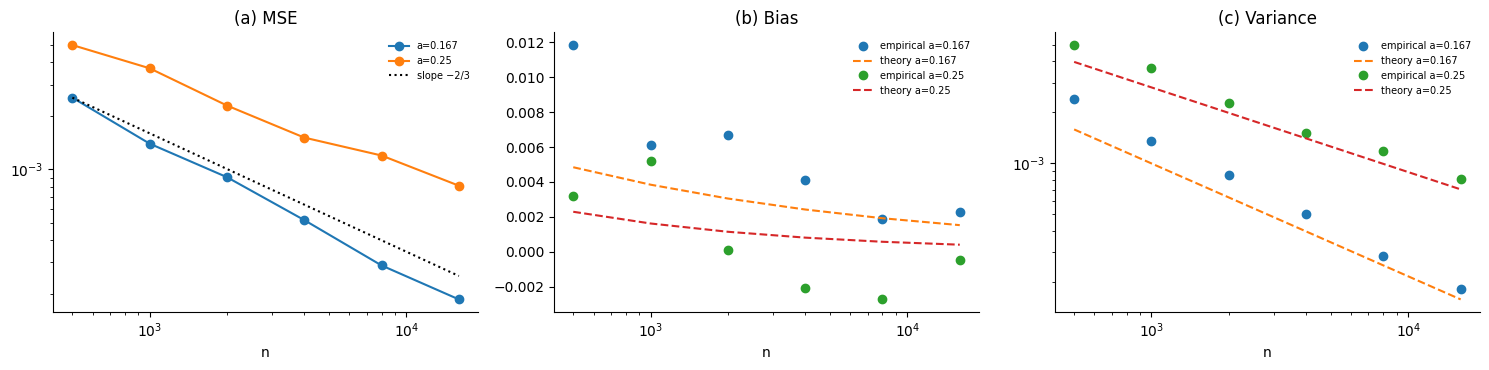

In [14]:
def sim_estimate(n, a, rng, u=np.array([.3, .2]), sigma=.5, reps=400):
    est = np.empty(reps); h = np.arange(1, n + 1) ** (-a)
    for r in range(reps):
        Xr = rng.normal(size=(n, 2)); Mr = np.sin(Xr[:, 0]) + .5 * Xr[:, 1] ** 2 + rng.normal(0, sigma, n)
        K = np.exp(-.5 * ((Xr - u) ** 2).sum(1) / h ** 2) / h ** 2
        est[r] = (K * Mr).sum() / K.sum()
    return est

u0 = np.array([.3, .2]); m_true = np.sin(u0[0]) + .5 * u0[1] ** 2
f_u = np.exp(-.5 * (u0 ** 2).sum()) / (2 * np.pi)
lap_m, grad_m, grad_f_over_f = -np.sin(u0[0]) + 1, np.array([np.cos(u0[0]), u0[1]]), -u0
rng = np.random.default_rng(11); sim = []
for a in (1/6, 1/4):
    for n in (500, 1000, 2000, 4000, 8000, 16000):
        e = sim_estimate(n, a, rng); hn = n ** (-a)
        sim.append(dict(a=round(a, 3), n=n, bias_emp=e.mean() - m_true,
                        bias_th=hn ** 2 / (2 * (1 - 2 * a)) * (lap_m + 2 * grad_m @ grad_f_over_f),
                        var_emp=e.var(), var_th=(1 / (4 * np.pi)) * .25 / ((1 + 2 * a) * n * hn ** 2 * f_u),
                        mse_emp=np.mean((e - m_true) ** 2)))
sim = pd.DataFrame(sim); display(sim.round(5))
for a, g in sim.groupby("a"):
    slope = np.polyfit(np.log(g.n), np.log(g.mse_emp), 1)[0]
    print(f"a = {a}: pente empirique log MSE ~ log n = {slope:.2f} (théorique : {-min(4*a, 1-2*a):.2f})")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, g in sim.groupby("a"):
    ax[0].loglog(g.n, g.mse_emp, "o-", label=f"a={a}"); ax[1].plot(g.n, g.bias_emp, "o", label=f"empirical a={a}"); ax[1].plot(g.n, g.bias_th, "--", label=f"theory a={a}")
    ax[2].loglog(g.n, g.var_emp, "o", label=f"empirical a={a}"); ax[2].loglog(g.n, g.var_th, "--", label=f"theory a={a}")
nn = np.array([500, 16000]); ax[0].loglog(nn, sim.mse_emp.iloc[0] * (nn / 500) ** (-2 / 3), "k:", label="slope −2/3")
ax[1].set_xscale("log")
for a_, t_ in zip(ax, ["(a) MSE", "(b) Bias", "(c) Variance"]): a_.set_title(t_); a_.set_xlabel("n"); a_.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/Fig_recursive_simulation.png", dpi=150); plt.show()

**Application en ligne au catalogue (prédiction puis mise à jour).** Les événements avec $M \ge M_c$ sont traités dans l'ordre chronologique. Avant d'intégrer l'événement $n$, on prédit sa magnitude à partir de $\hat m_{n-1}(X_n)$ : c'est une évaluation honnête, qui n'utilise que le passé.
On compare trois approches : $\beta_n = 1/n$ (le théorème), un pas constant $\beta = 0{,}002$ (oubli exponentiel, qui suit la non-stationnarité) et la moyenne cumulée. La fenêtre $h_n = h_0 n^{-1/6}$ est calibrée pour valoir 5 km à la fin du catalogue (même valeur que la CV par blocs).

,method,RMSE,MAE,n_eval,seconds_total
0,beta_n = 1/n,0.3885,0.3049,2412,0.1429
1,beta = 0.002 (forgetting),0.4005,0.3081,2412,0.1226
2,cumulative mean (baseline),0.4418,0.3536,2413,NaN


Mise à jour récursive : 0.14 ms par événement pour 7991 nœuds de grille
Carte récursive vs carte batch : corrélation 0.991, écart absolu médian 0.010


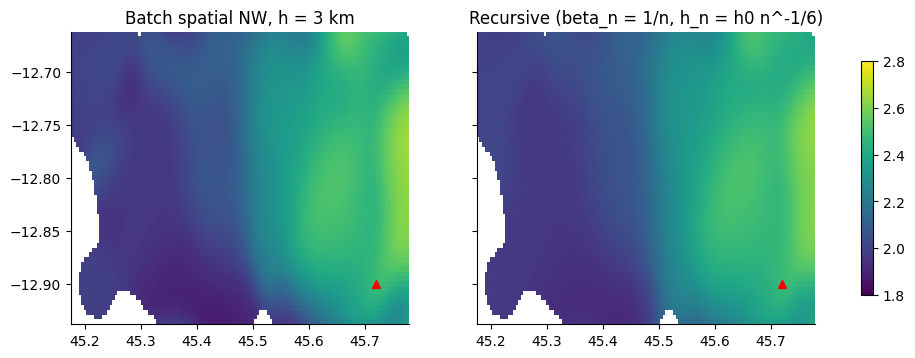

In [15]:
gridxy = np.c_[GX.ravel(), GY.ravel()]
h0 = HSF * len(d) ** (1 / 6)
res = {}
for label, beta in [("beta_n = 1/n", "harmonic"), ("beta = 0.002 (forgetting)", 0.002)]:
    sm = RecursiveMarkSmoother(np.c_[xs, ys], h0=h0, beta=beta)   # evaluated at event locations for prequential error
    preds = np.full(len(d), np.nan); t0 = time.perf_counter()
    for i in range(len(d)):
        if i > 0:
            f_i, p_i = sm.f[i], sm.phi[i]; preds[i] = p_i / f_i if f_i > 1e-12 else np.nan
        sm.update((xs[i], ys[i]), zs[i])
    res[label] = (preds, time.perf_counter() - t0)
cum_mean = np.r_[np.nan, np.cumsum(zs)[:-1] / np.arange(1, len(zs))]
burn = 200; mask = np.arange(len(d)) >= burn
rows = []
for label, (pr, dt) in res.items():
    ok = mask & np.isfinite(pr)
    rows.append(dict(method=label, RMSE=np.sqrt(np.mean((zs[ok] - pr[ok]) ** 2)), MAE=np.mean(np.abs(zs[ok] - pr[ok])), n_eval=int(ok.sum()), seconds_total=dt))
rows.append(dict(method="cumulative mean (baseline)", RMSE=np.sqrt(np.mean((zs[mask] - cum_mean[mask]) ** 2)), MAE=np.mean(np.abs(zs[mask] - cum_mean[mask])), n_eval=int(mask.sum())))
display(pd.DataFrame(rows).round(4))

# carte finale récursive vs lisseur spatial batch (h = 5 km)
rec = RecursiveMarkSmoother(gridxy, h0=h0); t0 = time.perf_counter()
for i in range(len(d)): rec.update((xs[i], ys[i]), zs[i])
dt = time.perf_counter() - t0
Wb = np.exp(-.5 * ((gridxy[:, None, 0] - xs) ** 2 + (gridxy[:, None, 1] - ys) ** 2) / HSF ** 2); swb = Wb.sum(1)
batch = np.where(swb > .5, Wb @ zs / np.maximum(swb, 1e-300), np.nan); recm = np.where(swb > .5, rec.predict(), np.nan)
ok = np.isfinite(batch) & np.isfinite(recm)
print(f"Mise à jour récursive : {1e3 * dt / len(d):.2f} ms par événement pour {len(gridxy)} nœuds de grille")
print(f"Carte récursive vs carte batch : corrélation {np.corrcoef(batch[ok], recm[ok])[0, 1]:.3f}, écart absolu médian {np.median(np.abs(batch[ok] - recm[ok])):.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a_, Zg, t_ in [(ax[0], batch, f"Batch spatial NW, h = {HSF:g} km"), (ax[1], recm, "Recursive (beta_n = 1/n, h_n = h0 n^-1/6)")]:
    im = a_.pcolormesh(LON, LAT, Zg.reshape(GX.shape), cmap="viridis", vmin=1.8, vmax=2.8, shading="auto"); a_.plot(*FANI, "r^"); a_.set_title(t_)
fig.colorbar(im, ax=ax, shrink=.8); plt.savefig(f"{OUT}/Fig_recursive_vs_batch.png", dpi=150, bbox_inches="tight"); plt.show()

## 10. Coût de calcul et scalabilité (commentaire 6)

On génère des catalogues synthétiques de $N$ événements en rééchantillonnant les hypocentres réels (avec un bruit de 0,5 km) et en tirant les temps au taux observé : un $N$ plus grand correspond à un catalogue plus long, à densité constante.
On compare le lisseur **dense** ($O(N^2)$) à la version **KD-tree** à noyau tronqué ($O(N \log N)$), traitée par blocs pour borner la mémoire.
Pour garder un temps d'exécution raisonnable, ce notebook s'arrête à $3 \times 10^5$ événements ; le script `s5_scalability.py` va jusqu'à $10^6$.

,N,kmeans_s,kmeans_MiB,tree_s,tree_MiB,dense_s,dense_MiB
0,1000,0.027,0.126,0.017,13.226,0.010,15.385
1,3000,0.237,0.335,0.125,106.663,0.110,137.455
2,10000,0.264,1.081,1.007,726.329,1.678,1526.005
3,30000,0.357,2.821,5.021,2517.019,NaN,NaN
4,100000,0.560,9.230,17.403,4391.210,NaN,NaN
5,300000,1.104,27.540,45.992,4487.465,NaN,NaN


Exposant empirique (KD-tree) : 1.11 | exposant (dense) : 2.23


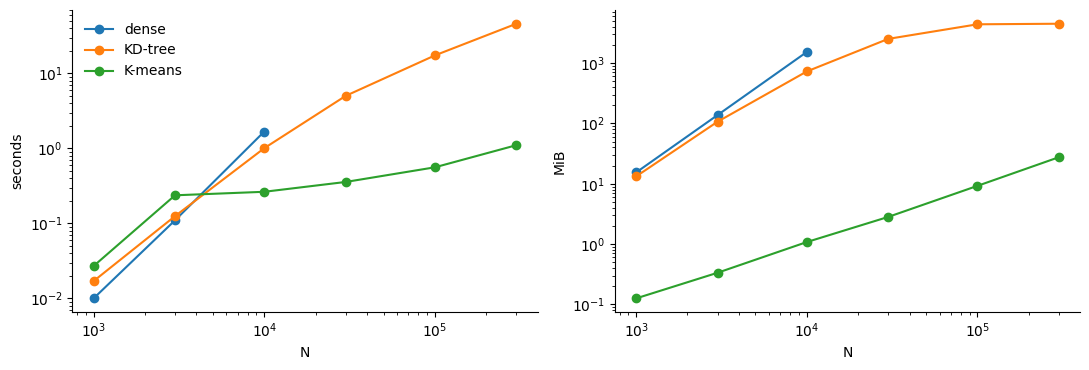

In [16]:
rate = len(c) / ((c.time.max() - c.time.min()).total_seconds() / 86400)
def synth(Nn, rng):
    i = rng.integers(0, len(c), Nn)
    return (c.x_km.values[i] + rng.normal(0, .5, Nn), c.y_km.values[i] + rng.normal(0, .5, Nn), c.Depth.values[i],
            np.sort(rng.uniform(0, Nn / rate, Nn)), c.Magnitude.values[i])
def measure(fn):
    tracemalloc.start(); t0 = time.perf_counter(); fn(); dt = time.perf_counter() - t0
    pk = tracemalloc.get_traced_memory()[1] / 2 ** 20; tracemalloc.stop(); return dt, pk
def nw_dense(x, y, t, z):
    W = np.exp(-.5 * (((x[:, None] - x) ** 2 + (y[:, None] - y) ** 2) / HSF ** 2 + (t[:, None] - t) ** 2 / HTF ** 2)); np.fill_diagonal(W, 0)
    return W @ z / W.sum(1)
def nw_tree(x, y, t, z, r=3.0, chunk=50_000):
    U = np.c_[x / HSF, y / HSF, t / HTF]; tree = cKDTree(U); num = np.zeros(len(z)); den = np.zeros(len(z))
    for s0 in range(0, len(z), chunk):
        D = cKDTree(U[s0:s0 + chunk]).sparse_distance_matrix(tree, r, output_type="ndarray")
        i, j, v = D["i"] + s0, D["j"], D["v"]; k = i != j; w = np.exp(-.5 * v[k] ** 2)
        num += np.bincount(i[k], w * z[j[k]], len(z)); den += np.bincount(i[k], w, len(z))
    return np.where(den > 0, num / np.maximum(den, 1e-300), np.nan)
rng = np.random.default_rng(0); sc_rows = []
for Nn in (1_000, 3_000, 10_000, 30_000, 100_000, 300_000):
    x_, y_, z_, t_, M_ = synth(Nn, rng); r = dict(N=Nn)
    r["kmeans_s"], r["kmeans_MiB"] = measure(lambda: KMeans(2, n_init=10, random_state=0).fit(np.c_[x_, y_, z_]))
    r["tree_s"], r["tree_MiB"] = measure(lambda: nw_tree(x_, y_, t_, M_))
    if Nn <= 10_000: r["dense_s"], r["dense_MiB"] = measure(lambda: nw_dense(x_, y_, t_, M_))
    sc_rows.append(r)
scal = pd.DataFrame(sc_rows).round(3); display(scal)
big = scal[scal.N >= 10_000]
print("Exposant empirique (KD-tree) :", round(np.polyfit(np.log10(big.N), np.log10(big.tree_s), 1)[0], 2),
      "| exposant (dense) :", round(np.polyfit(np.log10(scal.dropna().N), np.log10(scal.dropna().dense_s), 1)[0], 2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for col, lab in [("dense", "dense"), ("tree", "KD-tree"), ("kmeans", "K-means")]:
    s_ = scal.dropna(subset=[f"{col}_s"]); ax[0].loglog(s_.N, s_[f"{col}_s"], "o-", label=lab); ax[1].loglog(s_.N, s_[f"{col}_MiB"], "o-", label=lab)
ax[0].set_ylabel("seconds"); ax[1].set_ylabel("MiB"); ax[0].legend(frameon=False)
for a_ in ax: a_.set_xlabel("N")
plt.tight_layout(); plt.savefig(f"{OUT}/Fig_scalability.png", dpi=150); plt.show()

## 11. Synthèse et export
Les tableaux principaux sont écrits dans `out_nb/` au format CSV pour être repris dans le manuscrit.

In [27]:
for name, df_ in {"regions": tab_regions, "qc": pd.Series(qc).to_frame("n"), "clusters": tab_cl, "K_selection": sel,
                  "holt_winters": hw, "month_effects": months, "day_night": dn, "cv_best": best, "recursive_simulation": sim, "scalability": scal}.items():
    df_.to_csv(f"{OUT}/{name}.csv")
summary = {"events_raw": len(raw), "events_mayotte_clean": len(m), "Mc": MC, "events_complete": len(c), "K": Kopt,
           "final_bandwidth_km_days": [HSF, HTF], "period": [str(m.time.min()), str(m.time.max())]}
json.dump(summary, open(f"{OUT}/summary.json", "w"), indent=1); print(json.dumps(summary, indent=1))

{
 "events_raw": 16809,
 "events_mayotte_clean": 6329,
 "Mc": 1.7,
 "events_complete": 2613,
 "K": 2,
 "final_bandwidth_km_days": [
  3.0,
  1000.0
 ],
 "period": [
  "2021-03-01 00:43:00",
  "2025-09-30 07:25:00"
 ]
}
